# Inhibitory (basket) cell vs. Allen data

Builds the model interneuron, measures its electrophysiological features
(RMP, action potential, ISI, f-I slope, sag, membrane time constant), and
compares them against human Allen Cell Types recordings. This is the only
quantification for this cell type. Figures are written to
`results/single_cell_sim/interneuron/`.

Each experiment is rendered as a standalone figure and, via
`plot_all_experiments`, assembled into the combined layout
(`inhibitory_experiments`).

| Manuscript figure | Section |
| --- | --- |
| Fig. 6a | In-vitro experiments |
| Fig. 6b | Comparison to Allen data (violins) |

Notes on global NEURON state: every experiment cell pins `h.dt = 0.01` and
deletes all sections when done (loops delete each iteration), so `h.dt` never
leaks between cells and sections do not accumulate.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
from neuron import h
from neuron.units import ms, mV
from scipy import signal
from scipy.signal import find_peaks
from scipy.optimize import curve_fit
from matplotlib.gridspec import GridSpec

from hnn_tuning import ALLEN_DATA, HNN_CORE_MOD, results_dir
from hnn_tuning.cell_builder_utils import Cell, _get_inh_soma
from hnn_tuning.inh_mechs_utils import Mechs as inhmechs
from hnn_tuning.plot_utils import get_cmap_neurons
from hnn_tuning.model_data_comparison import exp_func, load_ephys_csv

pth_mod = str(HNN_CORE_MOD)
pth_data = str(ALLEN_DATA / 'interneuron')
figpth = results_dir('single_cell_sim', 'interneuron')
os.makedirs(figpth, exist_ok=True)

plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['pdf.fonttype'] = '42'
# global font sizes
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 10
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10

h.load_file('stdrun.hoc')

# inhibitory-cell build ingredients
section = dict()
section['soma'] = _get_inh_soma()
mech_class = inhmechs(pth_mod)
# Cumberland 2023 and Golomb 2007 parameters
inh_params = {'soma': {'nas_golomb2007': 0.11252 / 1.35,
                       'kdr_golomb2007': 0.225,
                       'kd_golomb2007': 0.00039,
                       'Ih_hay2011': 2e-5,
                       'pas': {'g': .0001,
                               'e': -70}}}


def get_inh_cell():
    """Build a fresh inhibitory (basket) cell with mechanisms inserted."""
    cell = Cell(section, cell_tree=None, cell_type='Inhibitory', gid=0)
    cell.build()
    cell = mech_class.add_mechs(cell, inh_params)
    return cell


# Allen reference data
inh_allen = load_ephys_csv(os.path.join(pth_data, 'ephys_inh.csv'))

ephys_measures = dict()

cm_neurons = get_cmap_neurons()            # interneuron colour = index 0
cols = np.array(([27, 158, 119], [217, 95, 2], [117, 112, 179], [231, 41, 138], [102, 166, 30])) / 255  # AP feature markers

plt.close('all')

## Fig. 6a — in-vitro experiments

### Plotting functions

Each function draws one experiment's panel into a supplied `ax`, reading the
results stored by the corresponding experiment cell below. Reused for both the
standalone figures and the combined layout, so the two can't drift apart.
`plot_all_experiments` rebuilds the original 2x3 GridSpec.

In [2]:
def _despine(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def plot_rmp(ax):
    ax.plot(rmp_t, rmp_v, color=cm_neurons[0], linewidth=1.5)
    ax.plot(rmp_t[-3], rmp_v[-3], 'o', color='k', markersize=7)
    ax.set_yticks([-70, -65])
    ax.set_ylabel('membrane potential (mV)')
    ax.set_xlabel('time (ms)')
    _despine(ax)


def plot_action_potential(ax):
    ax.plot(ap_t, ap_v, color=cm_neurons[0], linewidth=1.5)
    ax.set_ylim([-85, 50])
    ax.set_yticks([-70, 0, 50])
    ax.set_xlim([0, 20])
    ax.set_xticks([0, 10, 20])
    ax.set_xlabel('time (ms)')
    _despine(ax)


def plot_isi(ax):
    ax.plot(isi_t, isi_v, color=cm_neurons[0], linewidth=1.5)
    ax.set_xlim([0, 1000])
    ax.set_yticks([-70, 0, 50])
    ax.set_ylim([-80, 50])
    ax.set_xlabel('time (ms)')
    _despine(ax)


def plot_fr(ax):
    ax.plot(fr_ampl, fr_vals, color=cm_neurons[0], linewidth=1.5)
    ax.set_ylabel('FR (Hz)')
    ax.set_xlabel('amplitude (nA)')
    ax.set_xlim([fr_ampl[0], fr_ampl[-1]])
    ax.set_xticks([0.2, 0.4, 0.6])
    ax.set_ylim([80, 160])
    ax.set_yticks([80, 120, 160])
    _despine(ax)


def plot_sag(ax):
    for t_np, v_np in sag_traces:
        ax.plot(t_np, v_np, color=cm_neurons[0], linewidth=1.7)
    ax.set_xlim([0, 700])
    ax.set_yticks([-150, -100, -50])
    ax.set_ylabel('membrane potential (mV)')
    ax.set_xlabel('time (ms)')
    ax.set_ylim([-150, -50])
    _despine(ax)


def plot_all_experiments(fig=None):
    """Assemble every experiment panel into the original combined 2x3 layout.

    Returns the figure and the list of axes. Requires that all experiment cells
    above have already run (it reads their stored results).
    """
    if fig is None:
        fig = plt.figure(figsize=(8, 4), constrained_layout=True)
    gs = GridSpec(2, 3, figure=fig, width_ratios=[0.5, 0.5, 1.4])
    ax = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[0, 2]),
          fig.add_subplot(gs[1, :2]), fig.add_subplot(gs[1, 2])]
    plot_rmp(ax[0])
    plot_action_potential(ax[1])
    plot_isi(ax[2])
    plot_fr(ax[3])
    plot_sag(ax[4])
    return fig, ax

### Resting membrane potential (RMP)

RMP: -69.5971768675571


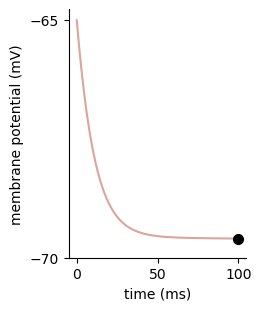

1

In [3]:
h.dt = 0.01
inh_cell = get_inh_cell()

t = h.Vector().record(h._ref_t)
soma_v = h.Vector().record(inh_cell._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.finitialize(-65 * mV)
h.continuerun(100 * ms)

ephys_measures['RMP'] = soma_v[-3]
print('RMP:', ephys_measures['RMP'], flush=True)

# store results for plotting
rmp_t = t.as_numpy().copy()
rmp_v = soma_v.as_numpy().copy()

fig, ax = plt.subplots(figsize=(2.5, 3), constrained_layout=True)
plot_rmp(ax)
plt.show()

h('forall delete_section()')

### Action potential

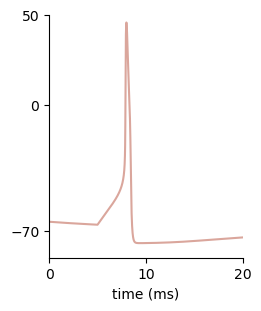

1

In [4]:
h.dt = 0.01
inh_cell = get_inh_cell()

stim = h.IClamp(inh_cell._nrn_sections['soma'](0.5))
stim.delay = 5
stim.dur = 3
stim.amp = 0.1
clamp_current = h.Vector().record(stim._ref_i)

t = h.Vector().record(h._ref_t)
v_soma = h.Vector().record(inh_cell._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.finitialize()
h.continuerun(20 * ms)

ap, properties = find_peaks(v_soma.as_numpy(), height=0, width=0)

v_np = v_soma.as_numpy()
t_np = t.as_numpy()
smooth_v = signal.savgol_filter(np.diff(v_np), 201, 3, mode='constant')

ap_thresh_idx = np.where(smooth_v / np.diff(t_np)[0] > 20)[0][0] + 1
ap_thresh = v_np[ap_thresh_idx]

if len(ap) > 0:
    ap_peak = properties['peak_heights'][0]
else:
    ap_peak = v_soma[-1]

start_ap = int(ap[0])
stop_ap = np.argmin(np.abs(t_np - (t_np[ap[0]] + 5)))
elbow_p = int(np.argmin(v_np[start_ap:stop_ap]) + start_ap)

upstroke = np.mean(np.gradient(v_np[ap_thresh_idx:int(ap[0])]))
downstroke = np.mean(np.gradient(v_np[int(ap[0]):elbow_p]))

ap_up_down = np.abs(upstroke / downstroke)

ap_width = properties['widths'][0] * h.dt
ephys_measures['ap_width'] = ap_width
ephys_measures['upstroke_downstroke'] = ap_up_down
ephys_measures['ap_threshold'] = v_soma[ap_thresh_idx]

# store results for plotting
ap_t = t.as_numpy().copy()
ap_v = v_soma.as_numpy().copy()
ap_elbow_p = elbow_p

fig, ax = plt.subplots(figsize=(2.5, 3), constrained_layout=True)
plot_action_potential(ax)
plt.show()

h('forall delete_section()')

### Inter-spike interval (ISI)

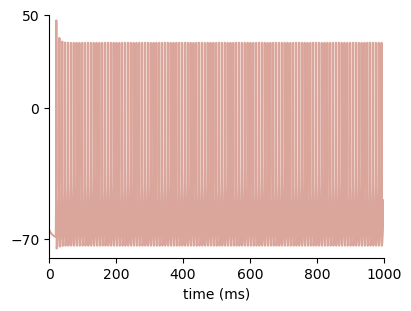

1

In [5]:
h.dt = 0.01
amp_isi = np.mean(inh_allen['max_amp_isi'].dropna().values)
inh_cell = get_inh_cell()
stim = h.IClamp(inh_cell._nrn_sections['soma'](0.5))
stim.delay = 20
stim.dur = 1000
stim.amp = amp_isi

t = h.Vector().record(h._ref_t)
soma_v = h.Vector().record(inh_cell._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.finitialize()
h.continuerun(1020 * ms)

aps = find_peaks(soma_v, height=0)[0]
ephys_measures['first_isi'] = np.diff(t.as_numpy()[aps])[0]
ephys_measures['mean_isi'] = np.mean(np.diff(t.as_numpy()[aps]))

# store results for plotting
isi_t = t.as_numpy().copy()
isi_v = soma_v.as_numpy().copy()

fig, ax = plt.subplots(figsize=(4, 3), constrained_layout=True)
plot_isi(ax)
plt.show()

h('forall delete_section()')

### Firing-rate slope (FI curve)

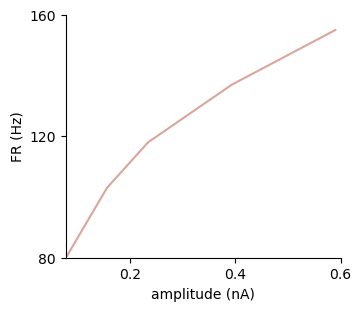

In [6]:
h.dt = 0.01
amp_isi = np.mean(inh_allen['max_amp_isi'].dropna().values)
l_stim = 1000
max_amp_isi = np.max(inh_allen['max_amp_isi'].dropna().values)

ampl = np.array([amp_isi / 3, amp_isi / 1.5, amp_isi, max_amp_isi / 1.5, max_amp_isi])

soma_v = np.zeros((len(ampl), int(1 / h.dt * l_stim + 1)))
fr = np.zeros_like(ampl)

for i, amp in enumerate(ampl):

    inh_cell = get_inh_cell()

    stim = h.IClamp(inh_cell._nrn_sections['soma'](0.5))
    stim.delay = 20
    stim.dur = 1000
    stim.amp = amp
    clamp_current = h.Vector().record(stim._ref_i)

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(inh_cell._nrn_sections['soma'](0.5)._ref_v)

    h.celsius = 37
    h.finitialize()
    h.continuerun((l_stim + stim.delay) * ms)

    pk = find_peaks(v_soma, height=0)
    fr[i] = len(pk[0])

    h('forall delete_section()')

pA = 0.001  # nA (convert nA to pA)
ephys_measures['FR_slope'] = np.polyfit(ampl, fr, 1)[0]
ephys_measures['FR_slope'] *= pA

# store results for plotting
fr_ampl = ampl.copy()
fr_vals = fr.copy()

fig, ax = plt.subplots(figsize=(3.5, 3), constrained_layout=True)
plot_fr(ax)
plt.show()

### Hyperpolarization (sag ratio and membrane time constant)

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn_tuning/model_data_comparison.py:18: RuntimeWarning: overflow encountered in exp
  return A * (1 - np.exp(-t / tau)) + C
/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn_tuning/model_data_comparison.py:18: RuntimeWarning: overflow encountered in multiply
  return A * (1 - np.exp(-t / tau)) + C


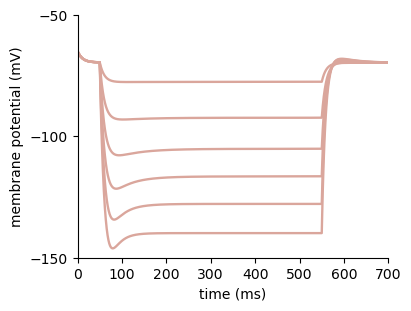

In [7]:
h.dt = 0.01
sag_stim_amp = np.unique(np.concatenate(inh_allen['sag_stim_amp'].dropna().values))
tau_ms = np.zeros_like(sag_stim_amp)
steady_state = np.zeros_like(sag_stim_amp)
min_membr_pot = np.zeros_like(sag_stim_amp)
v_bsl = np.zeros_like(sag_stim_amp)
sag_traces = []
for i, amp in enumerate(sag_stim_amp):
    inh_cell = get_inh_cell()

    h.distance(sec=inh_cell._nrn_sections['soma'])

    stim = h.IClamp(inh_cell._nrn_sections['soma'](0.5))
    stim.delay = 50
    stim.dur = 500
    stim.amp = amp

    v = h.Vector().record(inh_cell._nrn_sections['soma'](0.5)._ref_v)
    t = h.Vector().record(h._ref_t)

    h.celsius = 37
    h.finitialize()
    h.continuerun(700 * ms)

    v_np = v.as_numpy()
    t_np = t.as_numpy()

    # Sag ratio
    steady_idx = np.argmin(np.abs(t - ((stim.delay + stim.dur) * 0.9)))
    steady_state[i] = v_np[steady_idx]
    start_peak = np.argmin(np.abs(t_np - (t_np[np.argmin(v_np)] - 5 / 2)))  # from Allen ipfx https://github.com/AllenInstitute/ipfx/blob/c607a36e25618a6bb8ba5438c1cd945fb429e659/ipfx/subthresh_features.py#L131
    end_peak = np.argmin(np.abs(t_np - (t_np[np.argmin(v_np)] + 5 / 2)))
    min_membr_pot[i] = v_np[start_peak:end_peak].mean()
    bsl_end = np.argmin(np.abs(t - stim.delay))
    bsl_start = np.argmin(np.abs(t - (stim.delay - 10)))
    v_bsl[i] = np.mean(v_np[bsl_start:bsl_end])

    # Membrane time constant
    start_idx = np.where(t_np > stim.delay)[0][0]
    end_idx = np.where(t_np > stim.delay + stim.dur * 0.9)[0][0]      # steady state, see https://pmc.ncbi.nlm.nih.gov/articles/PMC2775376/

    t_rise = t_np[start_idx:end_idx] - stim.delay  # Time starting at 0
    v_rise = v_np[start_idx:end_idx]

    delta_v = np.mean(v_rise) - np.mean(v_np[:start_idx])
    # Fit the exponential function to the data
    popt, pcov = curve_fit(exp_func, t_rise, v_rise, p0=[2, abs(delta_v), v_rise[0]])
    tau_ms[i] = popt[0]  # This is the fitted time constant in ms

    # store this trace for plotting (copy: the hoc Vectors are reused each loop)
    sag_traces.append((t_np.copy(), v_np.copy()))

    h('forall delete_section()')

avg_tau_ms = np.mean(tau_ms)

ephys_measures['tau'] = avg_tau_ms
ephys_measures['sag'] = np.mean((min_membr_pot - steady_state) / (min_membr_pot - v_bsl))

fig, ax = plt.subplots(figsize=(4, 3), constrained_layout=True)
plot_sag(ax)
plt.show()

### Combined figure (original layout)

Reassembles all five experiment panels into the original 2x3 layout.

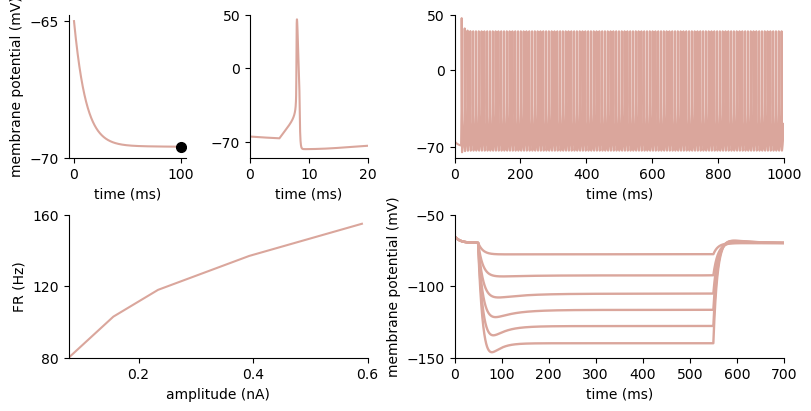

In [8]:
fig, axes = plot_all_experiments()
plt.show()
fig.savefig(figpth / 'inhibitory_experiments.png', dpi=300)
fig.savefig(figpth / 'inhibitory_experiments.pdf', dpi=300)
fig.savefig(figpth / 'inhibitory_experiments.svg', dpi=300)

plt.close('all')

## Fig. 6b — comparison to Allen data (violins)

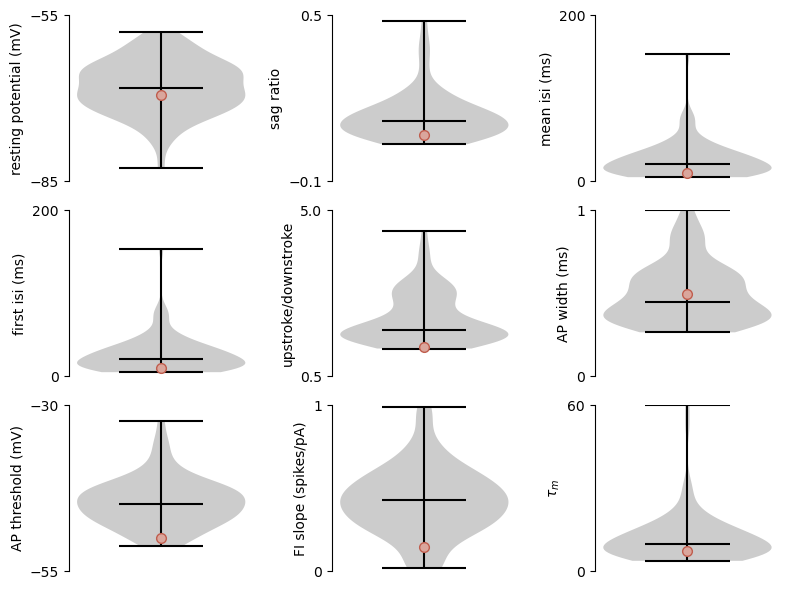

In [9]:
measures = ['RMP', 'sag', 'mean_isi', 'first_isi', 'upstroke_downstroke', 'ap_width', 'ap_threshold', 'FR_slope', 'tau']
label = ['resting potential (mV)', 'sag ratio', 'mean isi (ms)', 'first isi (ms)', 'upstroke/downstroke', 'AP width (ms)', 'AP threshold (mV)', 'FI slope (spikes/pA)', r'$\tau_{m}$']
ylims = [(-85, -55), (-0.1, .5), (0, 200), (0, 200), (.5, 5), (0, 1), (-55, -30), (0, 1), (0, 60)]
fig, ax = plt.subplots(3, 3, figsize=(8, 6))

ax = ax.ravel()
for i, m in enumerate(measures):

    data = inh_allen[m].dropna().values
    v = ax[i].violinplot(data, vert=True, showmeans=False, showmedians=True)

    ax[i].plot(1., ephys_measures[m], 'o', color=cm_neurons[0], markersize=7, markeredgecolor='#c05d4d')
    ax[i].set_ylabel(label[i])
    ax[i].set_ylim(ylims[i])
    ax[i].set_yticks(ylims[i])
    ax[i].spines['top'].set_visible(False)
    ax[i].spines['right'].set_visible(False)
    ax[i].set_xticks([])
    ax[i].spines['bottom'].set_visible(False)

    for pc in v['bodies']:
        pc.set_facecolor('black')
        pc.set_alpha(.2)
    v['cbars'].set_color('black')
    v['cmaxes'].set_color('black')
    v['cmins'].set_color('black')
    v['cmedians'].set_color('black')

fig.tight_layout()
fig.savefig(figpth / 'inhibitory_cell_vs_allen.png')
fig.savefig(figpth / 'inhibitory_cell_vs_allen.svg')
fig.savefig(figpth / 'inhibitory_cell_vs_allen.pdf')